<span style="text-align: center; color:#009999;">

# [LGBIO2050] - Medical Imaging
## *Non-Rigid Image Registration*
</span>

### Professors :   
- Prof. G. Kerckhofs  
- Prof. J. Lee
- Prof. B. Macq
- Prof. G. Duchêne
    
### Teaching assistants : 
- Pauline Hermans (pauline.hermans@uclouvain.be)
- Nicolas Delinte (nicolas.delinte@uclouvain.be)
- Simon Francois (simon.b.francois@uclouvain.be)

**2026-2027**

<span style="color:#009999;">
 
## 1. Guidelines and Deliverables
</span>

- This assignment is due on **11th November 2026**.
- The jupyter notebook containing the code and **detailed answers** to the questions must be delivered in an archive (.zip folder) on Moodle, with *"Markdown cells"* containing the answers to the questions and *"Code cells"* containing the code you implemented. The answers have to be written in English.
- This work must comply with the **EPL AI Guidelines** (available on Moodle) concerning the responsible use of AI in student work. Copying code or answers from other groups or from the internet is strictly prohibited. **Any source used for inspiration must be clearly acknowledged and referenced.**
- At the end of the semester, an **individual evaluation** will allow you to demonstrate that you have a good understanding of the challenge, both in terms of the code you have written and the answers to the reflection questions. Make sure that **all group members are familiar with each challenge and understand how it works**.
- The **presentation and overall formatting of your notebook** will also be taken into account in the assessment. Make sure to **write clean, efficient, well-structured code and comment it** appropriately to make it easy to understand. Your outputs and figures should also be clear and well-presented (do not forget titles, legends, etc. where appropriate). Pay particular attention to your answers to the questions as well. **Structure your explanations clearly** and use titles, subtitles, figures, and other relevant elements to make your **answers clear and precise**.  



<span style="color:#009999;">
 
## 2. Context
</span>


### Registration

The purpose of this challenge is to implement basic medical image registration tools. Aim of image registration is to align a ’moving’ image on a ’fixed’ or 'static' image by finding a spatial transformation mapping all pixels in the ’moving’ image to pixels in the ’fixed’ image.
Methods used in order to register medical images can be: 

- **Inter- vs Intra- patient.** Inter-patient methods register images captured on multiple patients while intra-patient methods register images captured on the same patient.
*In the context of this challenge, you will perform intra-patient image registration which is less sensitive to anatomical variations.*

- **Mono vs Multi- modal.** In the case of mono-modal registration, both ’fixed’ and ’moving’ images are of the same modality (MRI, PET, X-Rays,...). In the case of multi-modal registration, ’fixed’ and ’moving’ images are of different modalities (MRI/PET, PET/X-Rays,...). This second type of registration is useful to overlap different kind of information.
*In the context of this challenge, you will perform mono-modal image registration on CT-scans.*

- **Rigid vs non-rigid.** Rigid registration methods use a simple transform, uniformly applied over the entire image (like rotations or translations). In contrast, non-rigid registration methods allow to handle situations where the images to be registered have geometric differences that cannot be accounted by similarity (global translation, rotation, and scaling) transformations. In these cases, small variations in the images are taken into account in order to modify locally the deformation transform.
*In the context of this challenge, you will implement a non-rigid image registration tool.*


### Radiotherapy

Radiotherapy is a cancer treatment that uses ionizing radiation to destroy tumor cells while minimizing damage to surrounding healthy tissues. Before treatment, a planning CT scan is used to identify the tumor and determine the optimal distribution of the radiation dose, ensuring that the tumor receives the prescribed dose while limiting exposure to nearby organs. However, the patient's anatomy may change between treatment planning and actual radiation delivery due to breathing, changes in body position, or internal organ movement. As a result, the tumor may no longer be located exactly where it was during planning. Image registration is therefore essential to align the planning CT scan with an image acquired during treatment, allowing the tumor's current position to be identified and helping assess whether the planned radiation dose will still adequately cover the tumor.


<div class="alert alert-info">
    
**QUESTION 1**

In the following cell, import the images named ``CT_lung_planning.png`` and ``CT_lung_during_treatment.png``. Besides, import also the binary mask in ``Tumor_segmentation_for_planning.png`` file that gives the tumor's contour. Provide a preliminary visuallion of the problem by using the provided ``show_2images_and_difference`` function.

It is easy to see that these two images are not aligned. The purpose here is to automatically find the contour of the tumor on the moving image in order to assess the validity of the dose planning (i.e., by checking if the tumor is still entirely covered by the radiation beams). Thus, can you explain why registration is necessary in this context? Will the tumor be covered by the beam if its position is determined by the treatment planning?
</div>

Answer:

From the results we got from the code, we can see that the 3 matrices have the same dimensions, which means that the images and the mask are dimensionally compatible. From the images, we can understand why registration is necessary:
- Fixed image: represents the planning CT; the yellow outline shows the tumor's position during planning
- Moving image: represents the CT acquired during treatment; the tumor doesn't perfectly match the original yellow outline
- Difference: highlights the differences between the two images, the anatomical structures are misaligned, especially in the head, chest, and tumor regions.

The patient's anatomy and the tumor's position can change between treatment planning and radiation delivery, for example due to breathing or patient movements. If the radiation beam is aimed only at the position set during planning, it's not possible to guarantee that the entire tumor will be irradiated. This could lead to under-irradiation of part of the tumor and unnecessary exposure of the surrounding healthy tissues. Registration allows aligning the two CT images and estimating the tumor's current position, improving the accuracy of radiotherapy.

Fixed: (528, 512)
Moving: (528, 512)
Mask: (528, 512)


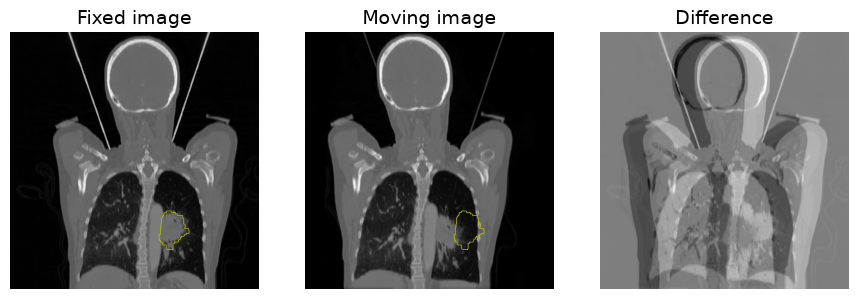

In [ ]:
import numpy as np
from skimage import measure
from skimage.io import imread
import matplotlib.pyplot as plt


def show_2images_and_difference(fixed, moving, mask=None): #the function expects two-dimensional images, but the images could be RGB or RGBA
    """
    Two image plot (fixed and moving) + difference (fixed-moving)

    Parameters
    ----------
    fixed : 2D array
        fixed image.
    moving : 2D array
        moving image.
    mask : 2D array, optional
        binary mask of the tumor. The default is None.

    Returns
    -------
    None
    """
    
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))

    for ax, img, title in zip(axes,[fixed, moving, fixed - moving],
                                ['Fixed image', 'Moving image', 'Difference']):
        ax.imshow(img, cmap='gray')
        ax.set_title(title, fontsize=14)
        ax.axis('off')

        if mask is not None and title != 'Difference':
            contour = measure.find_contours(mask.astype(float), 0)[0] #requires a 2D mask
            ax.plot(contour[:, 1], contour[:, 0], 'y-', linewidth=0.5)

    plt.tight_layout()
    plt.show()
    plt.close()

fixed = imread("imgs/CT_lung_planning.png")
moving = imread("imgs/CT_lung_during_treatment.png")
tumor_mask = imread("imgs/Tumor_segmentation_for_planning.png")

#convert images to 2D if they contain multiple channels
if fixed.ndim == 3:
    fixed = fixed[:, :, 0]

if moving.ndim == 3:
    moving = moving[:, :, 0]

if tumor_mask.ndim == 3:
    tumor_mask = tumor_mask[:, :, 0]

fixed = fixed.astype(float) #convert images to float for subtraction
moving = moving.astype(float) #convert images to float for subtraction
tumor_mask = tumor_mask > 0 #convert the tumor mask to binary

#check dimensions
print("Fixed:", fixed.shape)
print("Moving:", moving.shape)
print("Mask:", tumor_mask.shape)

show_2images_and_difference(fixed, moving, mask=tumor_mask)
from pathlib import Path



<span style="color:#009999;">
 
## 3. Non-Rigid Registration
### 3.1 First... Ridig Registration!
</span>

Rigid registration is a way to transform images. Such modifications are simple transforms uniformly applied on the entire image (rotations, translations, etc.). Those methods are not discussed in this challenge but they are crutial as a preprocessing step before applying non-rigid registration.
Execute the cell below to translate the moving image onto the fixed one. 

SSD = 361446545.00, tx = 1.00, ty = 0.00, theta = 0.000 degrees:   0%|          | 0/100 [00:00<?, ?it/s]

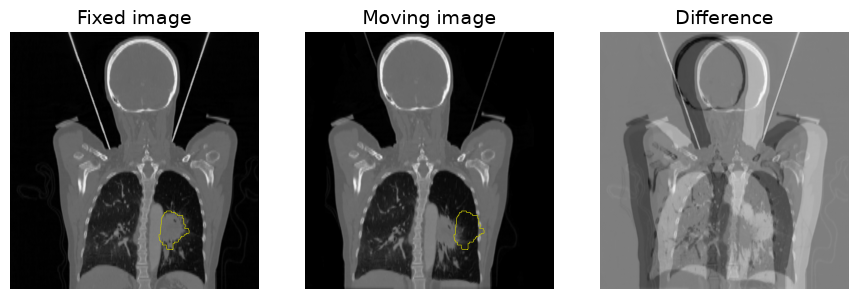

SSD = 296922921.88, tx = 11.00, ty = 0.00, theta = 3.438 degrees:  10%|█         | 10/100 [00:01<00:10,  8.55it/s]

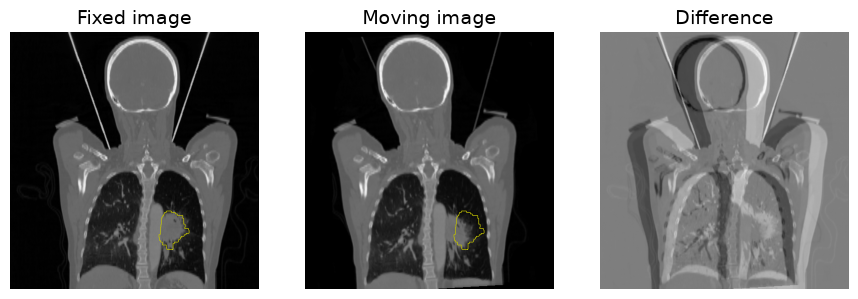

SSD = 222749164.63, tx = 21.00, ty = 0.00, theta = 5.730 degrees:  20%|██        | 20/100 [00:02<00:09,  8.37it/s]

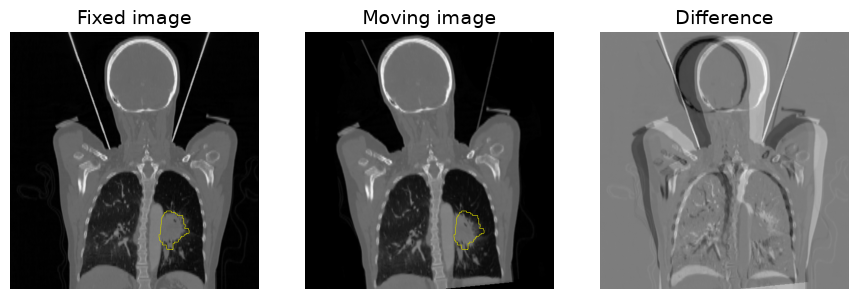

SSD = 154623433.02, tx = 31.00, ty = 0.00, theta = 2.865 degrees:  30%|███       | 30/100 [00:04<00:08,  8.39it/s]

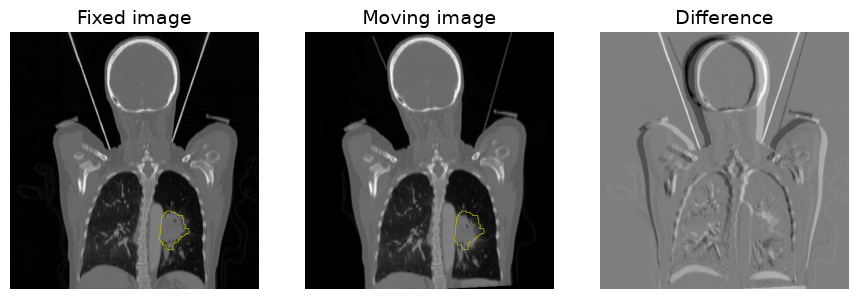

SSD = 56421949.12, tx = 41.00, ty = 2.00, theta = -0.573 degrees:  40%|████      | 40/100 [00:05<00:07,  8.43it/s]

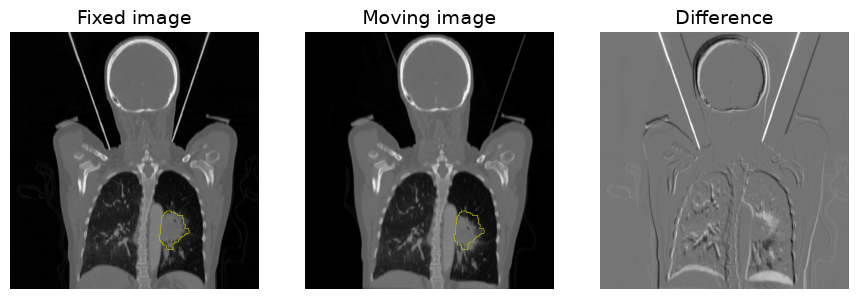

SSD = 43665433.22, tx = 43.38, ty = 2.56, theta = -0.573 degrees:  50%|█████     | 50/100 [00:07<00:05,  9.42it/s]

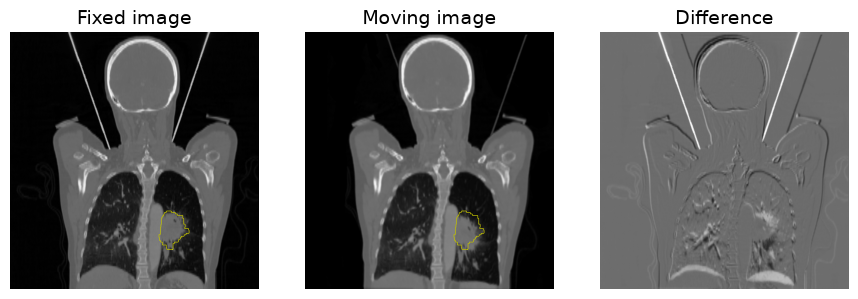

SSD = 43663217.74, tx = 43.37, ty = 2.54, theta = -0.564 degrees:  58%|█████▊    | 58/100 [00:08<00:05,  7.16it/s]


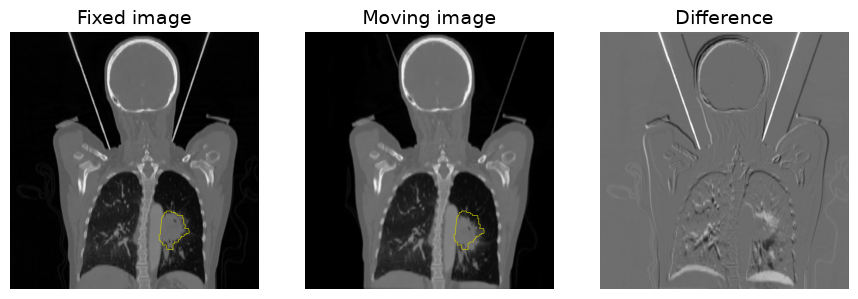

In [ ]:
#rigid regression --> preliminary step before the non-rigid registration
import numpy as np
from tqdm import tqdm
from scipy import ndimage


def SSD(im1, im2):
    """
    Compute the Sum of Squared Differences (SSD) between two images.

    Parameters
    ----------
    im1 : numpy.ndarray
        First image, represented as a numerical array.
    im2 : numpy.ndarray
        Second image, represented as a numerical array.

    Returns
    -------
    float or numpy scalar
        Sum of squared differences between the two images.
    """
    return np.sum((im1 - im2) ** 2)


def transform_image(moving, tx, ty, theta):
    """
    Apply a rigid transformation (rotation and translation) to the moving image.

    Parameters
    ----------
    moving : numpy.ndarray
        The moving image, represented as a numerical array.
    tx : float
        Horizontal translation in pixels.
    ty : float
        Vertical translation in pixels.
    theta : float
        Rotation angle in radians.

    Returns
    -------
    registered : numpy.ndarray
        Transformed image with the same shape as moving.
    """
    # Rotation around the image center
    rotated = ndimage.rotate(moving, np.degrees(theta),
                            reshape=False, order=1, mode='constant', cval=0)

    # Translation
    registered = ndimage.shift(rotated, shift=(ty, tx),
                            order=1, mode='constant', cval=0)

    return registered

#the function rigid_registration() tries to align the moving image to the fixed image using 2 transformations:
# 1- TRANSLATION --> move the image horizontally (tx) and vertically (ty)
# 2- ROTATION --> rotate the image by an angle theta
#The algorithm looks for the best parameters that minimize the SSD: the lower the SSD value,
#the smaller the overall intensity difference between the two images.
#At each iteration, the algorithm tries small changes to translation and rotation, keeping the ones that reduce the SSD.
def rigid_registration(fixed, moving, iter_max=100, step_trans=1.0, step_rot=0.01,
                       show_steps=True, mask=None):
    """
    Register a moving image to a fixed image using rigid transformations
    and iterative optimization of the Sum of Squared Differences (SSD).

    Parameters
    ----------
    fixed : numpy.ndarray
        Reference image to which the moving image is registered.
    moving : numpy.ndarray
        Image to transform and align with the fixed image.
    iter_max : int, optional
        Maximum number of optimization iterations. Default is 100.
    step_trans : float, optional
        Initial translation step size in pixels. Default is 1.0.
    step_rot : float, optional
        Initial rotation step size in radians. Default is 0.01.
    show_steps : bool, optional
        Whether to display intermediate registration results. Default is True.
    mask : 2D array, optional
        binary mask of the tumor. The default is None.

    Returns
    -------
    registered : numpy.ndarray
        Moving image after the estimated rigid transformation.
    tuple of float
        Estimated transformation parameters (tx, ty, theta).
    current_ssd : float or numpy scalar
        SSD between fixed and registered.
    """

    #initialization
    tx, ty, theta = 0.0, 0.0, 0.0
    registered = transform_image(moving, tx, ty, theta)
    current_ssd = SSD(fixed, registered)

    #iterative optimization
    pbar = tqdm(range(iter_max), desc='Iterative optimization')
    for i in pbar:

        improved = False

        #test positive and negative changes in each parameter
        for dtx, dty, dtheta in [(step_trans, 0, 0), (-step_trans, 0, 0), (0, step_trans, 0), (0, -step_trans, 0), (0, 0, step_rot), (0, 0, -step_rot)]:

            new_tx = tx + dtx
            new_ty = ty + dty
            new_theta = theta + dtheta

            candidate = transform_image(moving, new_tx, new_ty, new_theta)
            candidate_ssd = SSD(fixed, candidate)

            #keep the transformation if SSD decreases
            if candidate_ssd < current_ssd:
                tx, ty, theta = new_tx, new_ty, new_theta
                registered = candidate
                current_ssd = candidate_ssd
                improved = True
                #continue

        #if no improvement is found, reduce iteration steps size
        if not improved:
            step_trans /= 2
            step_rot /= 2

            #stop if steps size become very small
            if step_trans < 0.005 and step_rot < 0.00005:
                break

        pbar.set_description(f"SSD = {current_ssd:.2f}, tx = {tx:.2f}, "
                            f"ty = {ty:.2f}, theta = {np.degrees(theta):.3f} degrees")

        if show_steps and i%10==0:
            show_2images_and_difference(fixed, registered, mask=mask)

    return registered, (tx, ty, theta), current_ssd


# Apply rigid registration!!!!!
registered_rigid, params, SSD_val = rigid_registration(fixed, moving, iter_max=100, show_steps=True, mask=tumor_mask)
show_2images_and_difference(fixed, registered_rigid, mask=tumor_mask)

<div class="alert alert-info">
    
**QUESTION 2**

Comment the output of the rigid registration step on the moving image.
</div>

Answer: 

Rigid registration aims to improve the alignment between the fixed CT image and the moving one by applying translations and rotations, so we expect a reduction in the differences between the images and better alignment of the main anatomical structures. A limitation of rigid registration is that it can't correct local anatomical deformations caused by breathing or organ movement, so some differences may remain.

After running the last 2 lines of code, we get images that progressively show the alignment of anatomical structures. We can notice that:
- the main anatomical structures are better aligned
- the difference image shows a reduction in misalignment
- the tumor matches the yellow contour more closely
- there are still local differences (especially in the lung region and near the tumor) that can't be fixed with simple rotations and translations

We can say that rigid registration improves overall alignment but isn't enough to achieve perfect registration --> there's a need to use non-rigid registration. 


<span style="color:#009999;">

### 3.2 Demons
</span>


The next step consists in applying non-rigid registration on these images by deforming the pre-treatment image in order to get the best possible matching between images (this is mainly an estimation of deformations due to breathing). Unlike rigid registration methods, the demons algorithm allows to compute local transforms. This means that the mapping is no more defined by only two parameters but instead by a deformation field. This field is computed in every pixel based on local information (for instance the intensity and the gradient of the image).

The demons method aims to approximately minimize the SSD as explained in [reference](https://pdfs.semanticscholar.org/29b2/4a6e4438993e5ec5fea139274a9570d430e3.pdf). The algorithm you will implement is a greedy algorithm composed of the following steps:

**1. Initialization**
  - Define a deformed image as being equal to the moving image
  - Initialize the accumulated deformation field
  - Compute the gradient in the 'fixed' image  <font color=#009999> *Hint: use the gradient function from numpy* </font>
 
**2. Iterative process**
 - Gradient descent step on the SSD criterion
     - Compute the gradient in the ’deformed’ image
     - Compute the update deformation field $\overrightarrow{F}$ at each pixel with the adapted demons equation:
 $$ \overrightarrow{F} = \frac{(S-M) \times (\nabla S + \nabla M)}
 {(S-M)^2 + ||\nabla S + \nabla M||^2} $$
where $M$ is the value of the pixel in the moving image, $S$ is the value of the pixel in the static image, $\nabla M$ is the gradient of the moving image and $\nabla S$ is the gradient of the static image. <font color=#009999>*Hint: compute the X and Y components of the field individually*</font>
 - Smoothing step
     - Regularize the field with a Gaussian smoothing performed by convoluting the two components of the field with a 2D Gaussian kernel. Try different variances to regularize your field and compare your results. <font color=#009999> *Hint: use the function gaussian_filter from scipy.ndimage* </font>
     - Add the update deformation field to the accumulated field
     - Calculate the new ’deformed’ image by interpolation
     - Compute the SSD metric


**Remarks :**
- Note that the <samp>show_2images_and_field</samp> function allows you to visualize the deformation field. 
- In order to deform the moving image, you will have to give to each pixel $(x, y)$ the value in the moving image
located at $(x_d, y_d ) = (x, y) + d(x, y)$, where $d(x, y)$ is the deformation vector at pixel $(x, y)$. If $(x_d , y_d )$ does not correspond to the coordinate of a pixel, you will have to interpolate the value between surrounding pixels. <font color=#009999> *Hint: use the function scipy.ndimage.map_coordinates* </font> <br>

<div class="alert alert-info">

**QUESTION 3**

Apply non-rigid registration on these images by deforming the moving image in order to get the best possible matching between images (this is mainly an estimation of deformations due to breathing). Comment the output of the non-rigid registration on the moving image.
</div>

Answer:

The Demons algorithm performs non-rigid registration by calculating a local displacement field based on intensity differences and image gradients. Compared to rigid registration, this method allows us to account for local anatomical variations, particularly those caused by breathing in the lung area.

After applying the Demons algorithm, we can see that the moving image is locally deformed to better align with the fixed image. However, some differences are still visible, especially around the tumor; the displacement field shows irregular vectors with different directions and intensities, suggesting that the deformation isn't completely smooth.

The Gaussian filter helps regularize the displacement field and avoid overly irregular deformations. Increasing the smoothing parameter generally leads to more uniform deformations, while lower values allow for more local variations but can produce irregular displacement fields. Non-rigid registration can improve local alignment, but the smoothing parameter needs to be chosen carefully to achieve realistic anatomical deformations.

From the results obtained, we can say that some differences remain visible (especially around the tumor); moreover, the displacement field shows some irregularities --> even though non-rigid registration can improve local alignment, the result is not perfect.


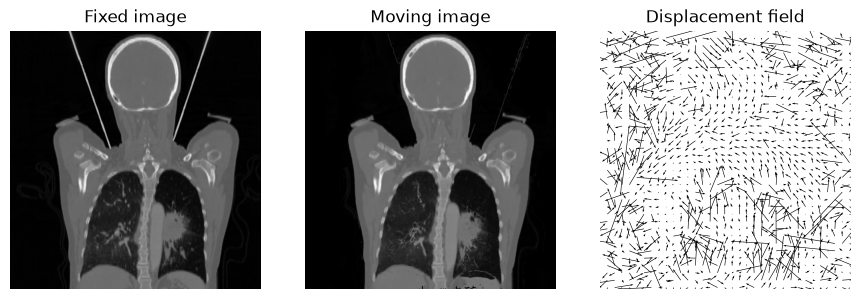

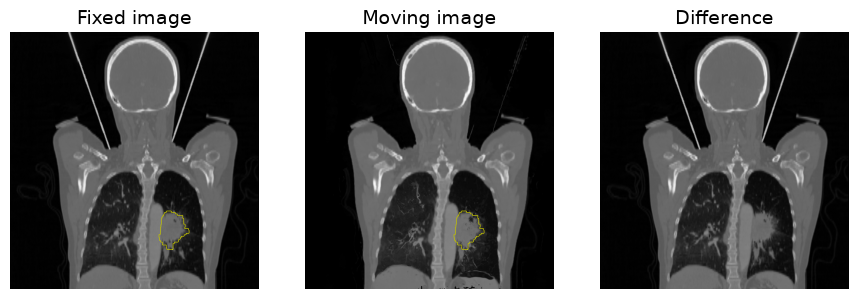

Sigma = 1.0, Final SSD = 417.82


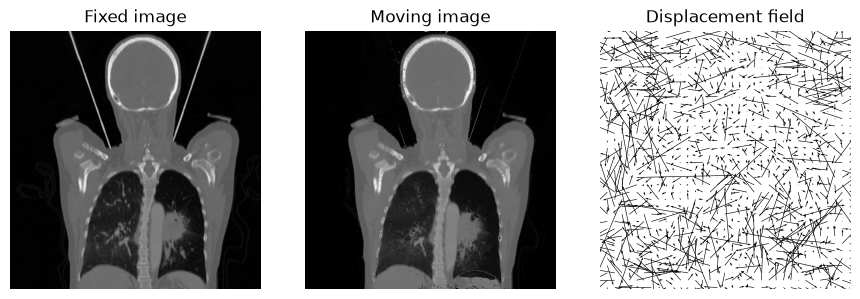

Sigma = 2.0, Final SSD = 386.65


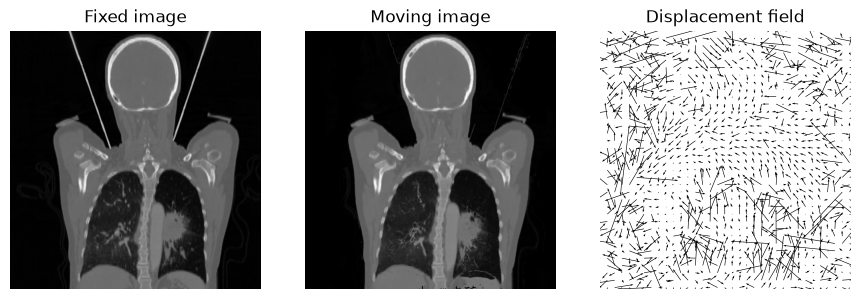

Sigma = 4.0, Final SSD = 377.16


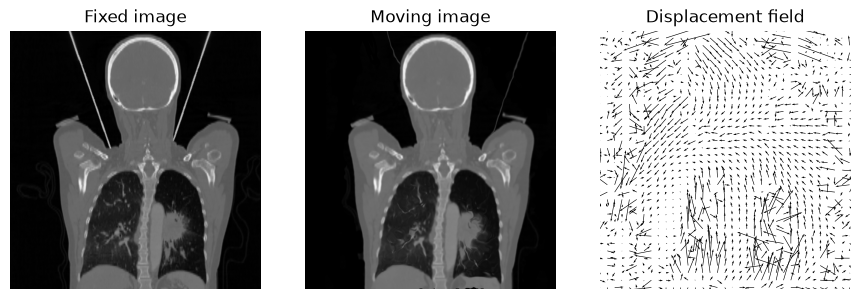

In [ ]:
#DEMONS algorithm: fixes the local deformations that rigid registration keeps
#how it works --> calculates a displacement for each pixel, the algorithm follows these steps (which are repeated for several iterations):
# 1- calculate the gradients of the fixed image
# 2- calculate the gradients of the deformed image
# 3- Demons formula to determine the local displacements
# 4- Gaussian filter to make the deformation field smoother
# 5- update the accumulated deformation field
# 6- reconstruct the deformed image through interpolation and SSD calculation.

def show_2images_and_field(fixed, moving, field_x, field_y):
    """
    Two image plot (fixed and moving) + deformation field.

    Parameters
    ----------
    fixed : numpy.ndarray
        Fixed image.
    moving : numpy.ndarray
        Moving image.
    field_x : numpy.ndarray
        Deformation field in X coordinates.
    field_y : numpy.ndarray
        Deformation field in Y coordinates.

    Returns
    -------
    None
    """

    fig, axes = plt.subplots(1, 3, figsize=(9, 3))

    axes[0].imshow(fixed, cmap='gray')
    axes[0].set_title('Fixed image')

    axes[1].imshow(moving, cmap='gray')
    axes[1].set_title('Moving image')

    rows, cols = fixed.shape
    x, y = np.meshgrid(np.arange(cols), np.arange(rows))

    axes[2].quiver(x[::15, ::15], y[::15, ::15], -field_x[::15, ::15], -field_y[::15, ::15], angles='xy', scale_units='xy', scale=0.2)
    axes[2].set_title('Displacement field')
    axes[2].set_xlim(0, cols)
    axes[2].set_ylim(rows, 0)
    axes[2].set_aspect('equal')

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

#we use registered_rigid() as the initial moving image since we have already applied the rigid registration
from scipy.ndimage import gaussian_filter, map_coordinates

def demons_registration(fixed, moving, iterations=100, sigma=2.0):

    #convert images to float and normalize their intensities
    fixed = fixed.astype(float) / 255.0
    moving = moving.astype(float) / 255.0

    #STEP 1
    #initially the deformed image is equal to the moving image
    deformed = moving.copy()

    #initialize the accumulated deformation field
    field_x = np.zeros_like(fixed)
    field_y = np.zeros_like(fixed)

    #compute the gradient of the fixed image
    grad_fixed_y, grad_fixed_x = np.gradient(fixed)

    #create the pixel coordinate grid
    rows, cols = fixed.shape
    y, x = np.meshgrid(np.arange(rows), np.arange(cols), indexing='ij')

    ssd_values = [] #to store SSD values

    #STEP 2: iterative process
    for i in range(iterations):

        grad_moving_y, grad_moving_x = np.gradient(deformed)
        difference = fixed - deformed #compute the intensity difference

        #sum of image gradients
        grad_x = grad_fixed_x + grad_moving_x
        grad_y = grad_fixed_y + grad_moving_y

        denominator = (difference**2 + grad_x**2 + grad_y**2) #compute the denominator of the Demons equation

        denominator = denominator + 1e-8 #avoid division by zero

        #compute the update deformation field
        update_x = difference * grad_x / denominator
        update_y = difference * grad_y / denominator

        #apply Gaussian smoothing to regularize the field
        update_x = gaussian_filter(update_x, sigma=sigma)
        update_y = gaussian_filter(update_y, sigma=sigma)

        field_x += update_x
        field_y += update_y

        #deform the moving image using interpolation
        deformed = map_coordinates(moving, [y + field_y, x + field_x], order=1, mode='constant', cval=0)

        #compute the Sum of Squared Differences
        ssd = np.sum((fixed - deformed)**2)
        ssd_values.append(ssd)

    return deformed, field_x, field_y, ssd_values

#the following code produces two figures: one with the deformation field and the other with the image of the differences
#apply non-rigid registration after rigid registration
registered_demons, field_x, field_y, ssd_values = demons_registration(fixed, registered_rigid, iterations=100, sigma=2.0)

#figure 1
show_2images_and_field(fixed, registered_demons, field_x, field_y)
#figure 2
show_2images_and_difference(fixed, registered_demons, mask=tumor_mask)

#comparison of different sigma values: 
# Sigma = 1.0	Variance = 1.0	Expected effect = more local and less regular deformations
# Sigma = 2.0	Variance = 4.0	Expected effect = compromise between flexibility and regularity
# Sigma = 4.0	Variance = 16.0	Expected effect = more uniform deformation field
for sigma in [1.0, 2.0, 4.0]:

    registered, fx, fy, ssd_history = demons_registration(fixed, registered_rigid, iterations=100, sigma=sigma)

    print(f"Sigma = {sigma}, Final SSD = {ssd_history[-1]:.2f}")

    show_2images_and_field(fixed, registered, fx, fy)

#!!! a lower SSD doesn’t automatically mean anatomically correct deformation.
#we also need to check that the deformation field is smooth and that the anatomical structures aren’t
#being distorted in unrealistic ways.

<div class="alert alert-info">

**QUESTION 4**

Which value of the variances (Gaussian kernel) seems to give the best result? Analyze the impact of a small/large value. Intuitively, does it make sense?
</div>

Answer:

From the results, we can see that increasing the variance of the Gaussian filter reduces the SSD. Among the values tested, a variance of 16 (σ = 4) produces the lowest SSD --> the best registration result in terms of intensity differences.

A small variance allows for more local deformations, but the displacement field can become irregular and sensitive to noise. A larger variance produces smoother deformations, but too much regularization can reduce the ability to correct small anatomical variations.

The result obtained makes intuitive sense because the Gaussian filter regularizes the displacement field, making the movements of neighboring pixels more similar. Therefore, a larger variance seems more suitable for these images, at least within the range of values we analyzed.

Sigma = 1.0, Variance = 1.0
Final SSD = 417.82


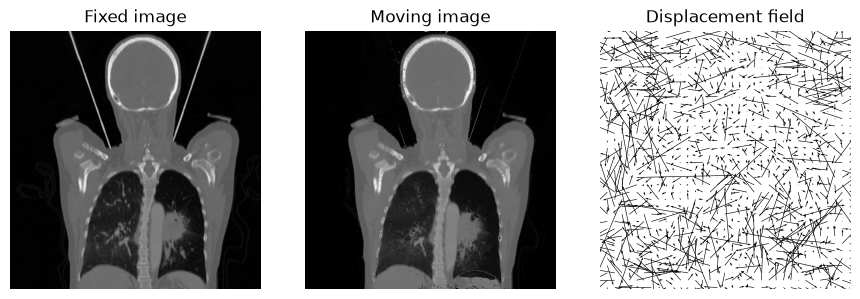

Sigma = 2.0, Variance = 4.0
Final SSD = 386.65


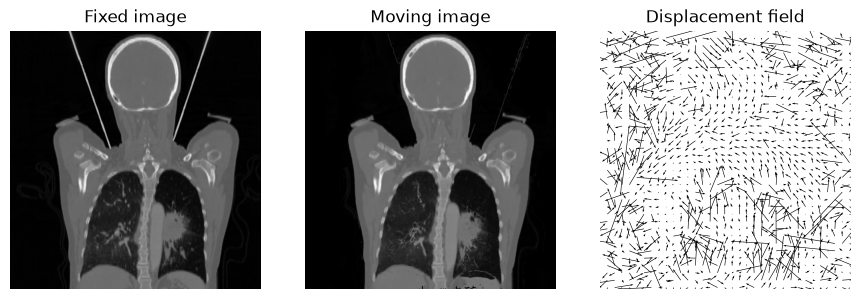

Sigma = 4.0, Variance = 16.0
Final SSD = 377.16


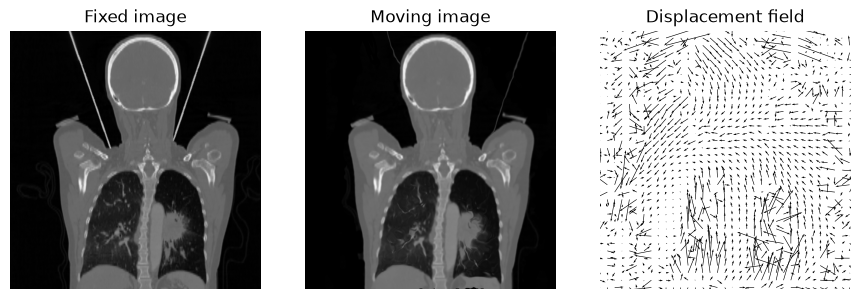

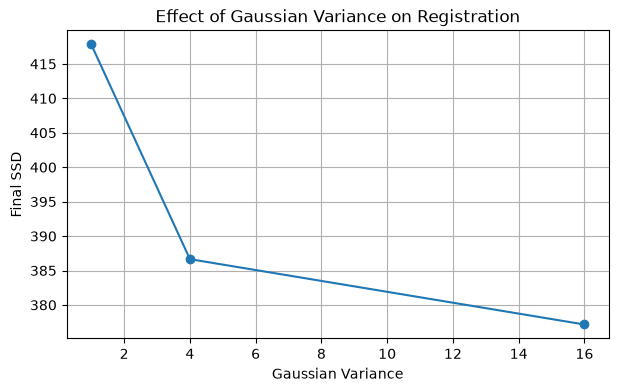

In [25]:
sigmas = [1.0, 2.0, 4.0]
ssd_results = []
for sigma in sigmas:
    registered, fx, fy, ssd_history = demons_registration(fixed, registered_rigid, iterations=100, sigma=sigma)

    ssd_results.append(ssd_history[-1])

    print(f"Sigma = {sigma}, Variance = {sigma**2}")
    print(f"Final SSD = {ssd_history[-1]:.2f}")

    show_2images_and_field(fixed, registered, fx, fy)

#plot the final SSD for different Gaussian variances
variances = np.array(sigmas)**2

plt.figure(figsize=(7, 4))
plt.plot(variances, ssd_results, marker='o')

plt.xlabel("Gaussian Variance")
plt.ylabel("Final SSD")
plt.title("Effect of Gaussian Variance on Registration")

plt.grid(True)
plt.show()

<div class="alert alert-info">

**QUESTION 5**

Also, try to apply the demons on the original images (with no rigid registration) and comment your results. Is the final result different? Why?
</div>

Answer:

Applying the Demons algorithm directly to the original images, without a preliminary rigid registration, we can see a worse result.
The moving image shows irregular anatomical deformations, especially in the head and lung regions, and the tumor is not properly aligned with its original outline.

The SSD decreases during the iterations in both cases, but it remains much higher without rigid registration (about 4200 compared to 377 with rigid registration). This happens because the Demons algorithm is based on local intensity differences and image gradients, making it difficult to correct large global misalignments. Rigid registration, on the other hand, gives a better initial alignment, allowing Demons to focus on smaller local deformations.

In conclusion, we can say that combining rigid and non-rigid registration produces a more accurate and anatomically consistent result.

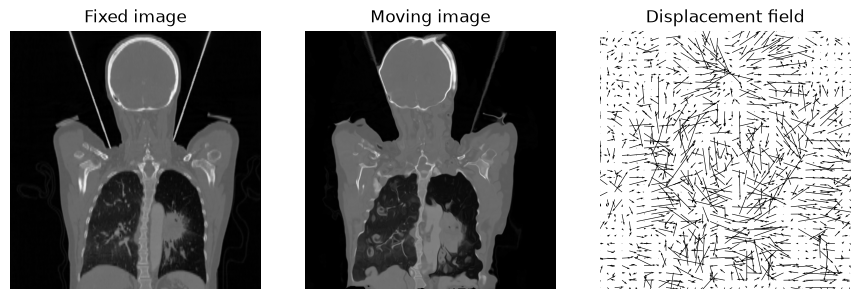

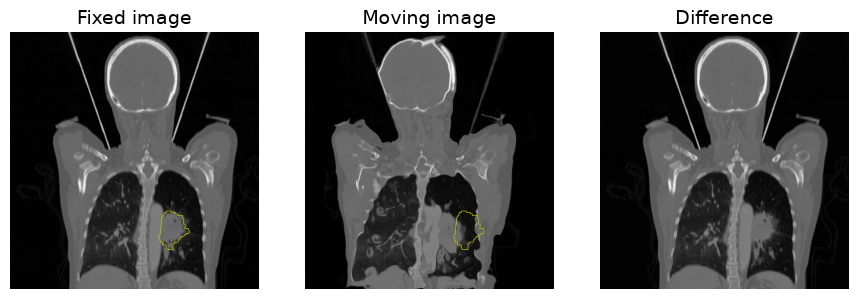

SSD with rigid registration: 377.1594775041006
SSD without rigid registration: 4200.456207021267


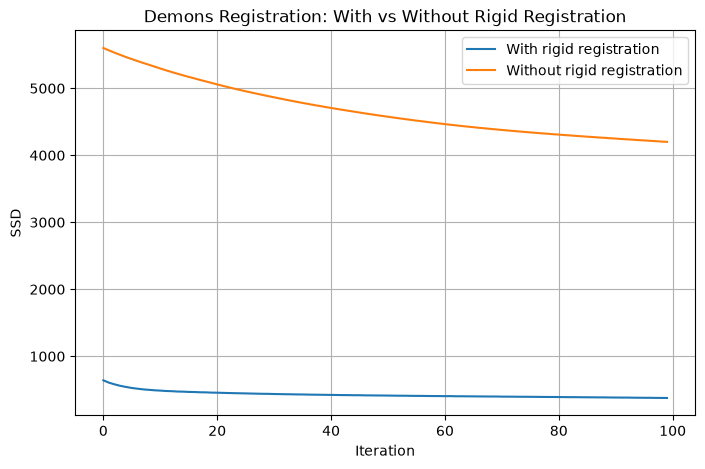

In [26]:
#apply Demons directly to the original images without preliminary rigid registration
registered_no_rigid, field_x_no_rigid, field_y_no_rigid, ssd_no_rigid = demons_registration(fixed, moving, iterations=100, sigma=4.0)

show_2images_and_field(fixed, registered_no_rigid, field_x_no_rigid, field_y_no_rigid)

show_2images_and_difference(fixed, registered_no_rigid, mask=tumor_mask) #display the difference between the images

registered_with_rigid, fx, fy, ssd_with_rigid = demons_registration(fixed, registered_rigid, iterations=100, sigma=4.0) #after rigid registration

print("SSD with rigid registration:", ssd_with_rigid[-1])
print("SSD without rigid registration:", ssd_no_rigid[-1])

#plot SSD evolution
plt.figure(figsize=(8, 5))
plt.plot(ssd_with_rigid, label="With rigid registration")
plt.plot(ssd_no_rigid, label="Without rigid registration")
plt.xlabel("Iteration")
plt.ylabel("SSD")
plt.title("Demons Registration: With vs Without Rigid Registration")
plt.legend()
plt.grid(True)
plt.show()

